# Analyze Deploy Log Notebook

## Summary

From this analysis we can monitor each deploy performance and find anomalies in the data. 

### Data and setup

The dataset has 18 rows (one per deploy or rollback job) and 16 columns. Only gap_since_uat_s has missing values, because it is recorded for Prod only.

In [1]:
import pandas as pd

df = pd.read_csv('../data/deploy_log.csv')
df.head()

,kind,environment,version,result,started_at,completed_at,duration_s,queued_s,deploy_step_s,outside_steps_s,gap_since_uat_s,commit_sha,actor,event,run_id,run_url
0,deploy,dev,sha-7c55acb,success,2026-10-30T03:46:17Z,2026-10-30T03:46:29Z,12,2,7,2,NaN,7c55acb,ahmadfauzanrinaufaldi,push,40999180235,https://github.com/ahmadfauzanrinaufaldi/relea...
1,deploy,uat,v0.1.0,success,2026-10-30T04:02:55Z,2026-10-30T04:03:06Z,11,2,6,3,NaN,7c55acb,ahmadfauzanrinaufaldi,push,41000651380,https://github.com/ahmadfauzanrinaufaldi/relea...
2,deploy,prod,v0.1.0,success,2026-10-30T04:05:53Z,2026-10-30T04:06:03Z,10,167,5,3,167.0,7c55acb,ahmadfauzanrinaufaldi,push,41000651380,https://github.com/ahmadfauzanrinaufaldi/relea...
3,deploy,dev,sha-44ef2f6,failure,2026-10-30T06:43:44Z,2026-10-30T06:43:53Z,9,2,5,2,NaN,44ef2f6,ahmadfauzanrinaufaldi,push,41015742537,https://github.com/ahmadfauzanrinaufaldi/relea...
4,deploy,uat,v0.2.0,failure,2026-10-30T06:51:17Z,2026-10-30T06:51:28Z,11,2,6,2,NaN,44ef2f6,ahmadfauzanrinaufaldi,push,41016493248,https://github.com/ahmadfauzanrinaufaldi/relea...


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   kind             18 non-null     object 
 1   environment      18 non-null     object 
 2   version          18 non-null     object 
 3   result           18 non-null     object 
 4   started_at       18 non-null     object 
 5   completed_at     18 non-null     object 
 6   duration_s       18 non-null     int64  
 7   queued_s         18 non-null     int64  
 8   deploy_step_s    18 non-null     int64  
 9   outside_steps_s  18 non-null     int64  
 10  gap_since_uat_s  3 non-null      float64
 11  commit_sha       18 non-null     object 
 12  actor            18 non-null     object 
 13  event            18 non-null     object 
 14  run_id           18 non-null     int64  
 15  run_url          18 non-null     object 
dtypes: float64(1), int64(5), object(10)
memory usage: 2.4+ KB


In [3]:
df["started_at"] = pd.to_datetime(df["started_at"])
df["completed_at"] = pd.to_datetime(df["completed_at"])
df.dtypes

kind                            object
environment                     object
version                         object
result                          object
started_at         datetime64[ns, UTC]
completed_at       datetime64[ns, UTC]
duration_s                       int64
queued_s                         int64
deploy_step_s                    int64
outside_steps_s                  int64
gap_since_uat_s                float64
commit_sha                      object
actor                           object
event                           object
run_id                           int64
run_url                         object
dtype: object

### Reliability
Dev succeeded in 9 of 10 deploys, UAT in 3 of 4, Prod in 3 of 3. Both failures came from the same bug (commit 44ef2f6).

In [4]:
deploys = df[df["kind"] == "deploy"].copy()
deploys["environment"].value_counts()

environment
dev     10
uat      4
prod     3
Name: count, dtype: int64

In [5]:
deploys.groupby("environment")["result"].value_counts()

environment  result 
dev          success    9
             failure    1
prod         success    3
uat          success    3
             failure    1
Name: count, dtype: int64

In [6]:
deploys["ok"] = deploys["result"] == "success"
deploys.groupby("environment")["ok"].mean()

environment
dev     0.90
prod    1.00
uat     0.75
Name: ok, dtype: float64

In [7]:
df[df["result"] == "failure"]


,kind,environment,version,result,started_at,completed_at,duration_s,queued_s,deploy_step_s,outside_steps_s,gap_since_uat_s,commit_sha,actor,event,run_id,run_url
3,deploy,dev,sha-44ef2f6,failure,2026-10-30 06:43:44+00:00,2026-10-30 06:43:53+00:00,9,2,5,2,NaN,44ef2f6,ahmadfauzanrinaufaldi,push,41015742537,https://github.com/ahmadfauzanrinaufaldi/relea...
4,deploy,uat,v0.2.0,failure,2026-10-30 06:51:17+00:00,2026-10-30 06:51:28+00:00,11,2,6,2,NaN,44ef2f6,ahmadfauzanrinaufaldi,push,41016493248,https://github.com/ahmadfauzanrinaufaldi/relea...


### Duration
Mean job duration is similar across environments (about 12s). duration_s covers the whole job, including time outside the deploy step, so it is a noisy measure of deploy speed.

In [8]:
deploys.groupby("environment")["duration_s"].agg(["count","mean", "max" , "min", "std"])

,count,mean,max,min,std
environment,,,,,
dev,10,12.30,22,9,3.653005
prod,3,12.00,15,10,2.645751
uat,4,11.75,13,11,0.957427


<Axes: title={'center': 'Mean Job Duration by Environment'}, xlabel='environment', ylabel='seconds'>

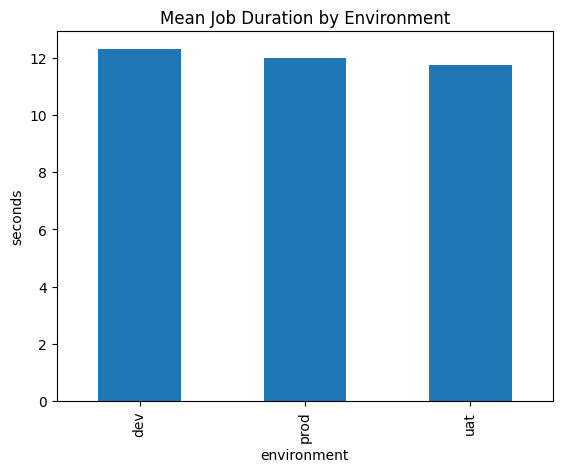

In [9]:
deploys.groupby("environment")["duration_s"].mean().plot(
    kind="bar", title="Mean Job Duration by Environment", ylabel="seconds", xlabel="environment")

The chart shows one point that stands out. To find out why, we extended export_deploy_log.py to also record the duration of each step

### Outlier Investigation

One Dev deploy (sha-993e25d) took 22s. Its deploy step took 7 s (normal range 5 to 8s), but time outside the steps was 13s (usually 2 to 4s). The cause is not known from this data.

In [10]:
dev = deploys[deploys["environment"] == "dev"]

<Axes: title={'center': 'Job duration of deploy-dev'}, xlabel='started_at'>

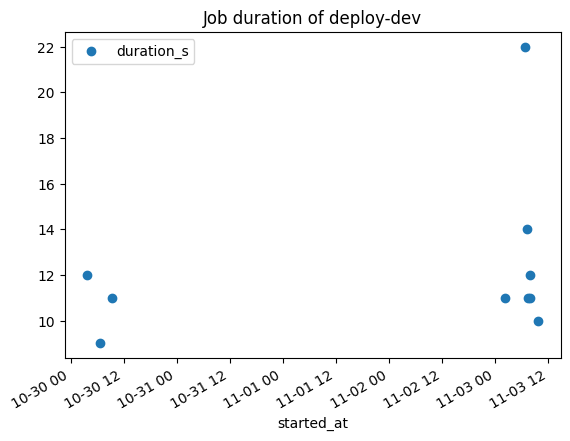

In [11]:
dev.plot(x="started_at", y="duration_s", style="o", title="Job duration of deploy-dev")

From this chart, there is a possible outlier data that we are still configuring the reason. From there we, improve our export_deploy_log.py to include all the timeframe of its deploy process not only the whole duration process

In [12]:
dev[["version", "duration_s", "queued_s", "deploy_step_s", "outside_steps_s"]]

,version,duration_s,queued_s,deploy_step_s,outside_steps_s
0,sha-7c55acb,12,2,7,2
3,sha-44ef2f6,9,2,5,2
6,sha-f756120,11,2,6,2
9,sha-3bc9200,11,3,5,4
10,sha-993e25d,22,2,7,13
11,sha-c36e356,14,2,8,3
12,sha-c7539b5,11,2,5,3
15,sha-16221ed,11,2,8,2
16,sha-6b067da,12,3,5,4
17,sha-af71718,10,2,5,2


There we found the anomaly, the sha-993e25d where the total duration is 22s and the outside_steps_s reach to 13s. Compared to other deploys, we can hypothesize that this deploy is an outlier where the outside steps usually 2 to 4 seconds only

<Axes: title={'center': 'Duration of deploy-dev'}, xlabel='started_at'>

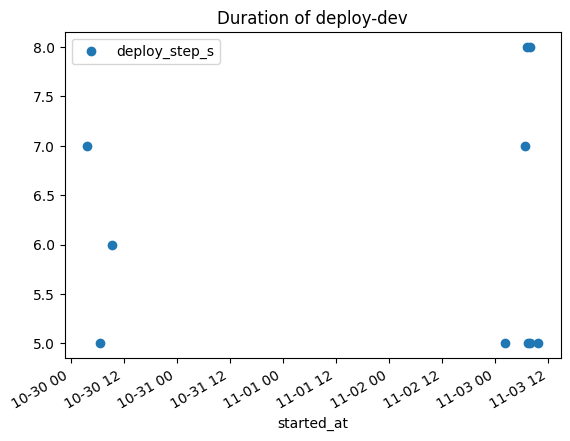

In [13]:
dev.plot(x="started_at", y="deploy_step_s", style="o", title="Duration of deploy-dev")

In [14]:
dev[["deploy_step_s", "outside_steps_s"]].agg(["count", "mean", "min", "max"])

,deploy_step_s,outside_steps_s
count,10.0,10.0
mean,6.1,3.7
min,5.0,2.0
max,8.0,13.0


### Approval Gap
The time between UAT finishing and Prod starting was 167, 70, and 73 seconds for the three releases. It dropped after the first release and stayed near 70 s. With only three data points this is an observation, not a trend.

In [15]:
deploys["gap_since_uat_s"].describe()

count      3.000000
mean     103.333333
std       55.157351
min       70.000000
25%       71.500000
50%       73.000000
75%      120.000000
max      167.000000
Name: gap_since_uat_s, dtype: float64

In [18]:
deploys[deploys["environment"] == "prod"][["version", "queued_s", "gap_since_uat_s"]]

,version,queued_s,gap_since_uat_s
2,v0.1.0,167,167.0
8,v0.2.1,70,70.0
14,v0.3.0,73,73.0


The results between queued_s and gap_since_uat_s are basically the same, concludes waiting time for approval, not only machine queues.

### Limitations and next steps

1. Not much data (only 18 rows, only 3 prod deploys) and 1 person in repository for exercise purposes.
2. duration_s includes time outside the deploy step
3. The cause of the sha-993e25d anomaly remains unknown

Next step could include lead time per commit, a scheduled export, and connecting Ansible to CD.